# 09 · Validación y robustez

**Preguntas que responde:** ¿la asociación corona → Y aparece donde no debería (control negativo)? ¿Tiene el signo
físico esperado? ¿Sobrevive a nueve decisiones razonables de depuración? ¿El peso del programa del Skinpass es del
programa o del periodo? ¿Qué tan fuerte tendría que ser un confusor no medido para anularla?

Implementa las secciones 9 (V1–V4, R1–R9) y 10 del plan congelado. Cada anclaje lleva su criterio de refutación,
escrito antes de verlo:

| # | Anclaje | Qué refutaría la conclusión |
|---|---|---|
| V1 | Control negativo: inclusiones del MC4 → Y | IC que excluye 0 y magnitud comparable a la de la corona |
| V2 | Signo físico: más corona → bending más negativo | Signo positivo con IC que excluye 0, o magnitud implausible |
| V3 | Robustez R1–R9 | La pendiente cambia de signo, o el orden programa > producto se invierte |
| V4 | Programa vs. periodo (día, semana) | No refuta; si dan lo mismo se escribe "programa/periodo" |

In [1]:
import sys
sys.path.insert(0, "..")

import warnings
warnings.filterwarnings("ignore", category=Warning, module="pandas")

import numpy as np
import pandas as pd

from src import inferencia as inf, resultados as res, skinpass as sk
from src import figuras_articulo as fa
from src.config import TABLAS_DIR
from src.resultados import fmt, guardar_cifras
from src.visualizacion import estilo_articulo, guardar_articulo

pd.set_option("display.width", 200, "display.max_columns", 30)
estilo_articulo()
m, pz, rs = sk.construir()
a = sk.analitica(m, "paso4")
a5 = sk.analitica(m, "paso5")
a5["celda_dm"] = a5["dimension"] + " | " + a5["mes_str"]
est = res.asociacion(a5)
e = est.iloc[0]

## V1. Control negativo: inclusiones del MC4 (origen en el acero, aguas arriba) → Y

In [2]:
nc = res.control_negativo(a5)
nc.to_csv(TABLAS_DIR / "control_negativo.csv", index=False)
nci = nc[nc["variable"].eq("inclusiones")].reset_index(drop=True)
print(f"Rollos con inclusiones: {int(a5['def_inclus'].sum()):,} ({100 * a5['def_inclus'].mean():.1f} %)")
print(f"Efecto de la corona por 1 DE dentro de celda: {e['efecto_por_sd']:.1f} kN [{e['efecto_por_sd_ic_inf']:.1f}, {e['efecto_por_sd_ic_sup']:.1f}]")
refuta_v1 = bool(((nci["ic_sup"] < 0) | (nci["ic_inf"] > 0)).any() and (nci["coef"].abs() >= abs(e["efecto_por_sd"])).any())
print("¿V1 refuta?", refuta_v1)
nci[["modelo", "coef", "ic_inf", "ic_sup", "p", "rollos", "grupos_cluster"]].round(3)

Rollos con inclusiones: 1,544 (3.6 %)
Efecto de la corona por 1 DE dentro de celda: -3.9 kN [-6.6, -1.2]
¿V1 refuta? False


,modelo,coef,ic_inf,ic_sup,p,rollos,grupos_cluster
0,Y ~ inclusiones + FE,-0.27,-9.289,8.750,0.953,41556,828
1,Y ~ inclusiones + corona + desv. T. enrollado ...,0.09,-8.944,9.123,0.984,41539,828


## V2. Consistencia física del signo

Argumento mecánico del equipo (la literatura revisada no fija el signo: Lenard, 2014, cap. 12, documenta que la
planeza no uniforme de entrada dificulta la laminación de temple, pero no discute la dirección del bending). En un
molino de cuatro rodillos, una banda que entra con más corona relativa (más gruesa al centro) necesita un claro
entre rodillos más abierto al centro para alargar sus fibras por igual; el doblado positivo de los rodillos de
trabajo cierra el centro, así que el lazo de planeza debería responder con un bending **más negativo**. Se
refutaría con una pendiente positiva cuyo IC excluya 0, o con una magnitud fuera de escala frente a la variación de Y.

In [3]:
cod = pd.factorize(a5["celda"])[0]
d5 = a5[a5.groupby("celda")["y_corr"].transform("size") > 1]
x_dentro = d5["corona_rel_pct"] - d5.groupby("celda")["corona_rel_pct"].transform("mean")
p10, p90 = x_dentro.quantile([0.10, 0.90])
cambio = e["coef"] * (p90 - p10)
print(f"Signo: {'negativo' if e['coef'] < 0 else 'positivo'}; IC 95 % [{e['ic_inf']:.1f}, {e['ic_sup']:.1f}] kN/pp")
print(f"Del p10 al p90 de la corona dentro de celda ({p10:.2f} a {p90:.2f} pp): cambio predicho en Y = {cambio:.1f} kN "
      f"(DE de Y = {a5['y_corr'].std():.0f} kN; rango intercuartil del bending real = {a5['bend_real'].quantile(.75) - a5['bend_real'].quantile(.25):.0f} kN)")
refuta_v2 = bool(e["ic_inf"] > 0)
print("¿V2 refuta?", refuta_v2)

Signo: negativo; IC 95 % [-6.6, -1.2] kN/pp
Del p10 al p90 de la corona dentro de celda (-0.57 a 0.38 pp): cambio predicho en Y = -3.7 kN (DE de Y = 191 kN; rango intercuartil del bending real = 239 kN)
¿V2 refuta? False


## V3 y V4. Robustez ante depuración (R1–R9) y programa vs. periodo

Para cada alternativa se recalculan las dos salidas de V3: la pendiente de corona (con su IC agrupado) y el orden
del exceso sobre el azar entre el grupo (programa, rodillo, día o semana) y el producto (20 permutaciones; la media
nula es muy estable). Una sola cosa cambia en cada renglón.

In [4]:
CORTE = sk.CORTE_CENSURA
p_lo, p_hi = a5["corona_rel_pct"].quantile([0.005, 0.995])

def r1b(d):
    d = d.copy(); d.loc[~d["corona_rel_pct"].between(p_lo, p_hi), "corona_rel_pct"] = np.nan; return d
def r1c(d):
    d = d.copy(); d.loc[d["corona_um"] > 600, "corona_rel_pct"] = np.nan; return d
def con_producto(nuevo):
    def f(d):
        d = d.copy(); d["producto"] = nuevo(d).astype("string").fillna("¿sin producto?")
        d["celda"] = d["producto"] + " | " + d["dimension"] + " | " + d["mes_str"]; return d
    return f
def corte(fecha):
    def f(d):
        d = d[d["y_corr"].notna() & d["bend_real"].notna()]
        return d[d["Fecha Inicio"] < fecha] if fecha is not None else d
    return f

m["paso4_r6"] = m["en_skp"] & (m["Fecha Inicio"] < CORTE) & m["y_corr"].notna() & m["bend_real"].notna()
specs = [
    ("Base", "plan congelado", "Base (plan)", dict()),
    ("R1", "corona en p0.5–p99.5", "R1 corona p0.5–p99.5", dict(preparar=r1b)),
    ("R1", "corona ≤ 600 µm", "R1 corona ≤ 600 µm", dict(preparar=r1c)),
    ("R2", "producto = Norma", "R2 producto = Norma", dict(preparar=con_producto(lambda d: d["norma_l"]))),
    ("R2", "producto = Norma | Grado | Subnorma", "R2 + Subnorma", dict(preparar=con_producto(lambda d: d["norma_grado"] + " | " + d["Subnorma"].astype("string").fillna("—")))),
    ("R3", "corte 15-nov", "R3 corte 15-nov", dict(base_paso="paso2", preparar=corte(pd.Timestamp("2025-11-15")))),
    ("R3", "sin corte de censura", "R3 sin corte", dict(base_paso="paso2", preparar=corte(None))),
    ("R4", "Y de la primera pieza", "R4 primera pieza", dict(preparar=lambda d: d.assign(y_corr=d["y_primera"]))),
    ("R4", "excluir rollos divididos", "R4 sin divididos", dict(preparar=lambda d: d[~d["dividido"]])),
    ("R5", "excluir preset = 0", "R5 sin preset 0", dict(preparar=lambda d: d[~d["preset_cero"]])),
    ("R6", "incluir rollos sin SKP_PSQ en la ruta", "R6 + sin ruta SKP", dict(base_paso="paso4_r6")),
    ("R7", "agregar |cuña| relativa", "R7 + cuña", dict(cov_extra=["cuna_abs_rel_pct"])),
    ("R8", "excluir preset > máximo bending real", "R8 sin preset alto", dict(preparar=lambda d: d[~d["preset_alto"]])),
    ("R9", "rodillo de trabajo en vez de programa", "R9 rodillo", dict(grupo="rodillo_trabajo")),
    ("V4", "día del Skinpass en vez de programa", "V4 día", dict(grupo="dia_skp")),
    ("V4", "semana del Skinpass en vez de programa", "V4 semana", dict(grupo="semana_skp")),
]
filas = []
for rob, alt, etiqueta, kw in specs:
    r = res.variante(m, rob, alt, **kw)
    r["etiqueta"] = etiqueta
    filas.append(r)
mv = pd.DataFrame(filas)
mv.to_csv(TABLAS_DIR / "robustez_multiverso.csv", index=False)
cambia_signo = bool((mv["coef"] > 0).any())
ic_cruza = int((mv["ic_sup"] >= 0).sum())
invierte = bool((~mv["programa_mayor_que_producto"]).any())
print(f"¿Alguna pendiente positiva? {cambia_signo} · IC que incluyen 0: {ic_cruza} de {len(mv)} · "
      f"¿se invierte el orden grupo > producto? {invierte}")
mv[["etiqueta", "coef", "ic_inf", "ic_sup", "rollos", "grupos", "exceso_producto", "exceso_grupo"]].round(3)

¿Alguna pendiente positiva? False · IC que incluyen 0: 1 de 16 · ¿se invierte el orden grupo > producto? False


,etiqueta,coef,ic_inf,ic_sup,rollos,grupos,exceso_producto,exceso_grupo
0,Base (plan),-3.901,-6.594,-1.209,41539,828,0.088,0.219
1,R1 corona p0.5–p99.5,-3.987,-7.060,-0.915,41106,824,0.088,0.219
2,R1 corona ≤ 600 µm,-4.106,-6.921,-1.292,41463,827,0.088,0.219
3,R2 producto = Norma,-5.712,-8.770,-2.655,42826,830,0.023,0.270
4,R2 + Subnorma,-3.857,-6.541,-1.173,41376,828,0.090,0.217
5,R3 corte 15-nov,-4.947,-8.658,-1.236,39325,786,0.088,0.221
6,R3 sin corte,-2.177,-4.471,0.116,44388,856,0.089,0.222
7,R4 primera pieza,-3.985,-6.705,-1.265,41539,828,0.088,0.217
8,R4 sin divididos,-4.899,-8.057,-1.740,33995,683,0.053,0.222
9,R5 sin preset 0,-4.249,-7.216,-1.283,36737,818,0.093,0.240


### V4 con intervalo: el programa contra el día, la semana y el rodillo de trabajo

In [5]:
v4 = []
for g in ["programa_skp", "dia_skp", "semana_skp", "rodillo_trabajo"]:
    t = inf.exceso_sobre_azar(a, "y_corr", ["tipo", "producto", "dimension", g], n_perm=100, n_boot=200)
    t["grupo"] = g
    v4.append(t)
v4 = pd.concat(v4, ignore_index=True)
v4.to_csv(TABLAS_DIR / "descomposicion_v4_periodo.csv", index=False)
v4[v4["nivel"].isin(["programa_skp", "dia_skp", "semana_skp", "rodillo_trabajo"])][
    ["nivel", "fraccion_observada", "media_nula", "exceso", "exceso_ic_inf", "exceso_ic_sup", "grupos_en_el_nivel"]].round(4)

,nivel,fraccion_observada,media_nula,exceso,exceso_ic_inf,exceso_ic_sup,grupos_en_el_nivel
3,programa_skp,0.6144,0.3936,0.2207,0.2051,0.2364,20710
7,dia_skp,0.5681,0.3631,0.2050,0.1923,0.2178,19133
11,semana_skp,0.3548,0.2211,0.1338,0.1201,0.1474,12152
15,rodillo_trabajo,0.3409,0.2086,0.1323,0.1184,0.1461,11704


## 10. Confusión no medida: valor de robustez de Cinelli y Hazlett (2020)

Confusores no medidos: planeza de entrada, estado de rodillos del MC4 y del Skinpass, decisiones del operador.
Referencia observada: el **producto** (el bloque de efectos fijos de producto dentro de dimensión × mes). Pregunta:
¿un confusor tan fuerte como el producto anularía la pendiente?

In [6]:
ch = inf.sensibilidad_ch(a5, "y_corr", "corona_rel_pct", ["dev_te"], "celda", "celda_dm",
                         coef=e["coef"], se=e["se"], gl=e["gl_resid"])
ch["k_que_anula"] = inf.k_que_anula(ch["r2_D_ref"], ch["r2_Y_ref"], e["coef"], e["se"], e["gl_resid"])
pd.Series(ch).to_csv(TABLAS_DIR / "sensibilidad_cinelli_hazlett.csv")
print({k: round(v, 5) for k, v in ch.items()})
anula = (ch["r2_D_confusor_1x"] >= ch["RV_q1"]) and (ch["r2_Y_confusor_1x"] >= ch["RV_q1"])
print("¿Un confusor 1× producto podría anular la pendiente?", bool(anula or np.sign(ch["coef_ajustado_1x"]) != np.sign(e["coef"])))

{'t': np.float64(-2.84418), 'gl': np.int64(37086), 'RV_q1': np.float64(0.01466), 'RV_q1_alfa05': np.float64(0.00458), 'r2_D_ref': 0.34016, 'r2_Y_ref': 0.24822, 'r2_D_confusor_1x': 0.51552, 'r2_Y_confusor_1x': 1.0, 'sesgo_max_1x': np.float64(272.49598), 'coef_ajustado_1x': np.float64(268.59448), 'k_que_anula': 0.02498}
¿Un confusor 1× producto podría anular la pendiente? True


## Figura de validación (R4) y cifras para el texto

{'VCuatroExcesoProg': '22.1',
 'VCuatroExcesoProgIC': '[20.5, 23.6]',
 'VCuatroProductoProg': '8.8',
 'VCuatroExcesoDia': '20.5',
 'VCuatroExcesoDiaIC': '[19.2, 21.8]',
 'VCuatroProductoDia': '8.8',
 'VCuatroExcesoSemana': '13.4',
 'VCuatroExcesoSemanaIC': '[12.0, 14.7]',
 'VCuatroProductoSemana': '8.8',
 'VCuatroExcesoRodillo': '13.2',
 'VCuatroExcesoRodilloIC': '[11.8, 14.6]',
 'VCuatroProductoRodillo': '8.8',
 'NInclusiones': '1,544',
 'PctInclusiones': '3.6',
 'VUnoCoef': '−0.3',
 'VUnoIC': '[−9.3, 8.7]',
 'VUnoP': '0.95',
 'VUnoCoefAj': '0.1',
 'VUnoICAj': '[−8.9, 9.1]',
 'VDosCambio': '−3.7',
 'VDosPdiez': '−0.57',
 'VDosPnoventa': '0.38',
 'YDEAsoc': '191',
 'BendRealIQR': '239',
 'NVariantes': '15',
 'NVariantesICCero': '1',
 'PendMvMin': '−5.7',
 'PendMvMax': '−2.2',
 'ExcProdMvMin': '2.3',
 'ExcProdMvMax': '12.5',
 'ExcGrupoMvMin': '13.2',
 'ExcGrupoMvMax': '27.0',
 'CHRV': '1.47',
 'CHRVa': '0.46',
 'CHRDRef': '34.0',
 'CHRYRef': '24.8',
 'CHRDConf': '51.6',
 'CHRYConf': '10

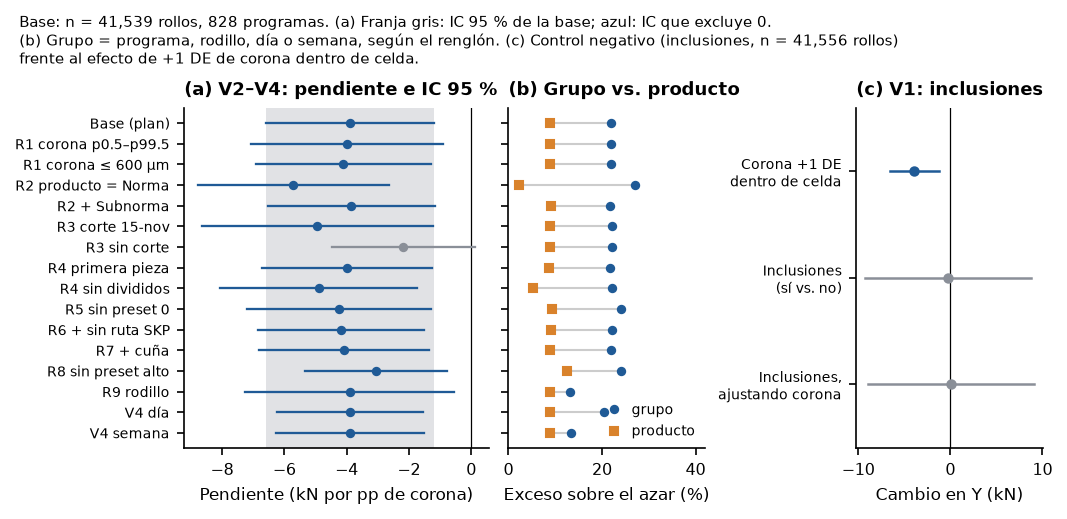

In [7]:
fig = fa.fig_validacion(mv, nci, e)
guardar_articulo(fig, "fig_r4_validacion")
V = v4.set_index(["grupo", "nivel"])
def exc(g):
    r = V.loc[(g, g)]
    return fmt(100 * r["exceso"], 1), f"[{fmt(100 * r['exceso_ic_inf'], 1)}, {fmt(100 * r['exceso_ic_sup'], 1)}]"
c = {}
for g, k in [("programa_skp", "Prog"), ("dia_skp", "Dia"), ("semana_skp", "Semana"), ("rodillo_trabajo", "Rodillo")]:
    c[f"VCuatroExceso{k}"], c[f"VCuatroExceso{k}IC"] = exc(g)
    c[f"VCuatroProducto{k}"] = fmt(100 * V.loc[(g, "producto"), "exceso"], 1)
n1 = nci.iloc[0]; n2 = nci.iloc[1]
c.update({
    "NInclusiones": fmt(int(a5["def_inclus"].sum()), 0), "PctInclusiones": fmt(100 * a5["def_inclus"].mean(), 1),
    "VUnoCoef": fmt(n1["coef"], 1), "VUnoIC": f"[{fmt(n1['ic_inf'], 1)}, {fmt(n1['ic_sup'], 1)}]", "VUnoP": f"{n1['p']:.2f}",
    "VUnoCoefAj": fmt(n2["coef"], 1), "VUnoICAj": f"[{fmt(n2['ic_inf'], 1)}, {fmt(n2['ic_sup'], 1)}]",
    "VDosCambio": fmt(cambio, 1), "VDosPdiez": fmt(p10, 2), "VDosPnoventa": fmt(p90, 2),
    "YDEAsoc": fmt(a5["y_corr"].std(), 0), "BendRealIQR": fmt(a5["bend_real"].quantile(.75) - a5["bend_real"].quantile(.25), 0),
    "NVariantes": fmt(len(mv) - 1, 0), "NVariantesICCero": fmt(ic_cruza, 0),
    "PendMvMin": fmt(mv["coef"].min(), 1), "PendMvMax": fmt(mv["coef"].max(), 1),
    "ExcProdMvMin": fmt(100 * mv["exceso_producto"].min(), 1), "ExcProdMvMax": fmt(100 * mv["exceso_producto"].max(), 1),
    "ExcGrupoMvMin": fmt(100 * mv["exceso_grupo"].min(), 1), "ExcGrupoMvMax": fmt(100 * mv["exceso_grupo"].max(), 1),
    "CHRV": f"{100 * ch['RV_q1']:.2f}", "CHRVa": f"{100 * ch['RV_q1_alfa05']:.2f}",
    "CHRDRef": f"{100 * ch['r2_D_ref']:.1f}", "CHRYRef": f"{100 * ch['r2_Y_ref']:.1f}",
    "CHRDConf": f"{100 * ch['r2_D_confusor_1x']:.1f}", "CHRYConf": f"{100 * ch['r2_Y_confusor_1x']:.1f}",
    "CHKAnula": f"{ch['k_que_anula']:.3f}", "CHUnoEntre": fmt(1 / ch["k_que_anula"], 0),
})
guardar_cifras(c)
c